<a href="https://colab.research.google.com/github/kavyasree4494/OIBSIP/blob/main/OIBSIP_DataAnalytics_L1_EDARetailSales_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df=pd.read_csv("retail_sales_dataset.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

print("LOAD DATASET AND PERFORM INITIAL INSPECTION",'\n')
print(df.head(),'\n')
print("shape:",df.shape,'\n')
print("column dtypes:",df.dtypes,'\n')
print("null value:",df.isnull().sum(),'\n')
print("DESCRIPTIVE STATISTICS",'\n')
print(df.describe(),'\n')

LOAD DATASET AND PERFORM INITIAL INSPECTION 

        Date  CustomerID ProductCategory   Price  Quantity  TotalAmount
0 2022-04-13         109         Apparel  192.00         2       384.00
1 2023-03-12           5           Books   40.65         8       325.20
2 2024-05-10         119      Home Goods  402.67         7      2818.69
3 2022-09-28          33           Books  385.63         6      2313.78
4 2022-04-17         118            Food  369.47         1       369.47 

shape: (1000, 6) 

column dtypes: Date               datetime64[ns]
CustomerID                  int64
ProductCategory            object
Price                     float64
Quantity                    int64
TotalAmount               float64
dtype: object 

null value: Date               0
CustomerID         0
ProductCategory    0
Price              0
Quantity           0
TotalAmount        0
dtype: int64 

DESCRIPTIVE STATISTICS 

                             Date   CustomerID        Price     Quantity  \
count       

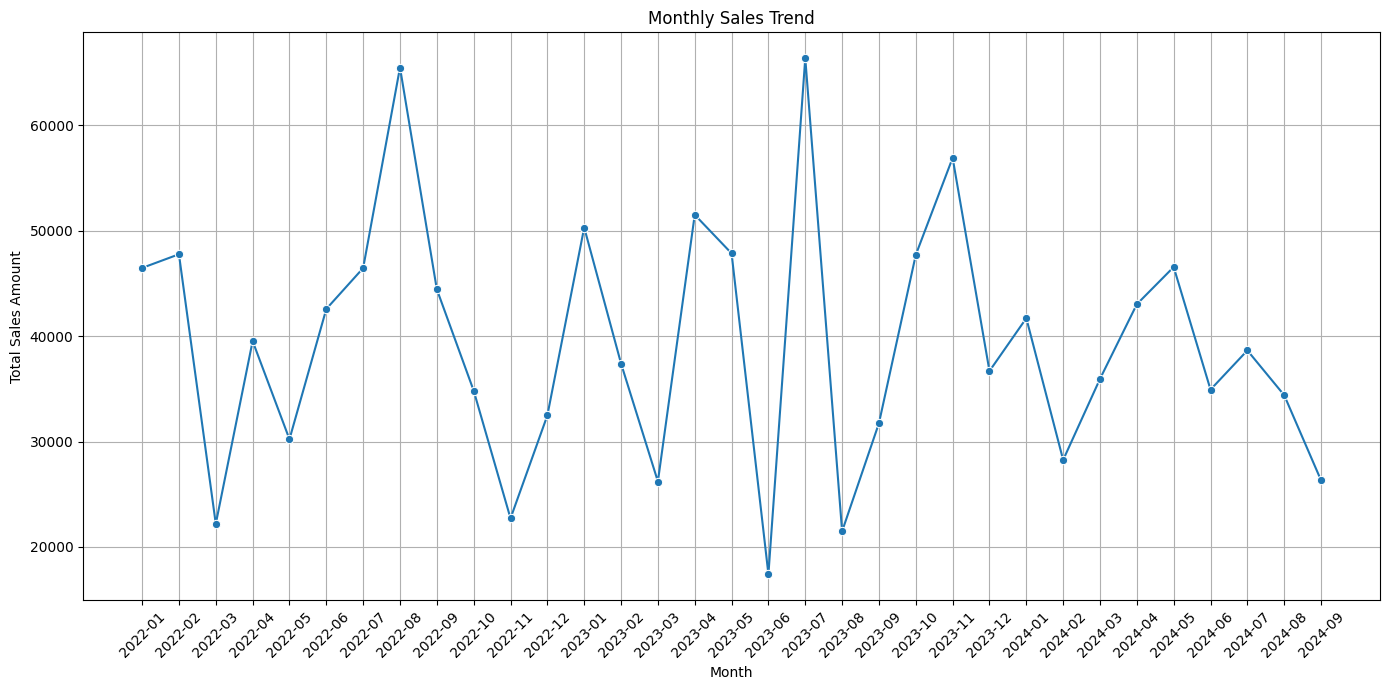

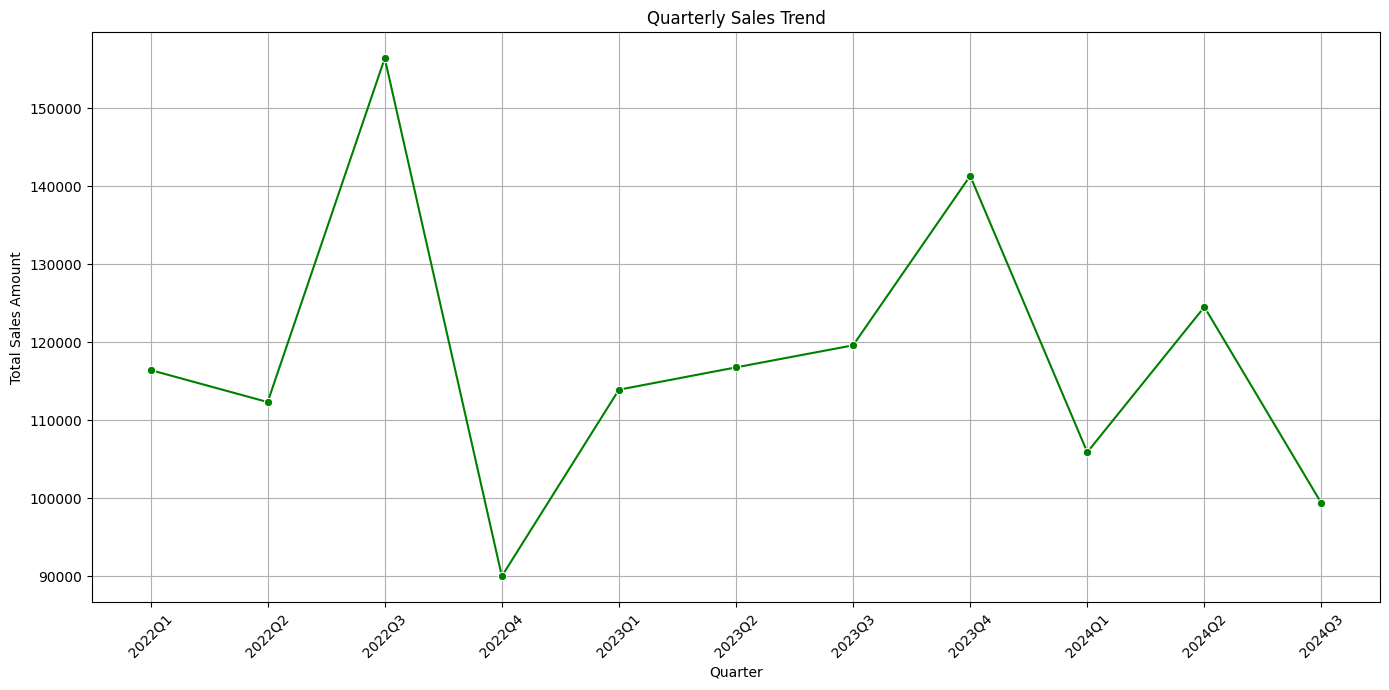

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
df['Month'] = df['Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['TotalAmount'].sum().reset_index()
monthly_sales['Month'] = monthly_sales['Month'].astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q')
quarterly_sales = df.groupby('Quarter')['TotalAmount'].sum().reset_index()
quarterly_sales['Quarter'] = quarterly_sales['Quarter'].astype(str)
plt.figure(figsize=(14, 7))
sns.lineplot(x='Month', y='TotalAmount', data=monthly_sales, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(14, 7))
sns.lineplot(x='Quarter', y='TotalAmount', data=quarterly_sales, marker='o', color='green')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

#### Observations from Sales Trends:
- **Monthly Sales Trend:** The monthly sales trend shows fluctuations. We can observe periods of growth and decline, indicating potential seasonality or impact of specific events within the year. For example, there might be peaks in certain months and troughs in others.
- **Quarterly Sales Trend:** The quarterly sales trend provides a broader view, smoothing out some monthly variations. This trend helps identify overall seasonal patterns, such as stronger sales in specific quarters (e.g., Q4 for holiday shopping) or consistent growth/decline over a longer period.

These charts help us understand the seasonality and overall growth (or decline) in sales over time. Further analysis could involve identifying specific peaks or troughs and investigating the reasons behind them.

### Customer Demographics Analysis: Age Groups and Gender Breakdown

In [ ]:
import numpy as np

# Generate dummy Age and Gender data for each CustomerID
np.random.seed(42)
unique_customer_ids = df['CustomerID'].unique()
customer_demographics = {
    'CustomerID': unique_customer_ids,
    'Age': np.random.randint(18, 70, len(unique_customer_ids)),
    'Gender': np.random.choice(['Male', 'Female', 'Other'], len(unique_customer_ids), p=[0.48, 0.48, 0.04])
}
customer_demographics_df = pd.DataFrame(customer_demographics)

df = df.drop(columns=[col for col in df.columns if col.startswith('Age') or col.startswith('Gender')], errors='ignore')

df = pd.merge(df, customer_demographics_df, on='CustomerID', how='left')

print("DataFrame with dummy Age and Gender columns:")
display(df.head())

DataFrame with dummy Age and Gender columns:


,Date,CustomerID,ProductCategory,Price,Quantity,TotalAmount,Month,Quarter,Age,Gender
0,2022-04-13,109,Apparel,192.00,2,384.00,2022-04,2022Q2,56,Female
1,2023-03-12,5,Books,40.65,8,325.20,2023-03,2023Q1,69,Male
2,2024-05-10,119,Home Goods,402.67,7,2818.69,2024-05,2024Q2,46,Female
3,2022-09-28,33,Books,385.63,6,2313.78,2022-09,2022Q3,32,Male
4,2022-04-17,118,Food,369.47,1,369.47,2022-04,2022Q2,60,Male


/tmp/ipykernel_1163/3886818430.py:5: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(df['Age'], bins=10, kde=True, palette='viridis')


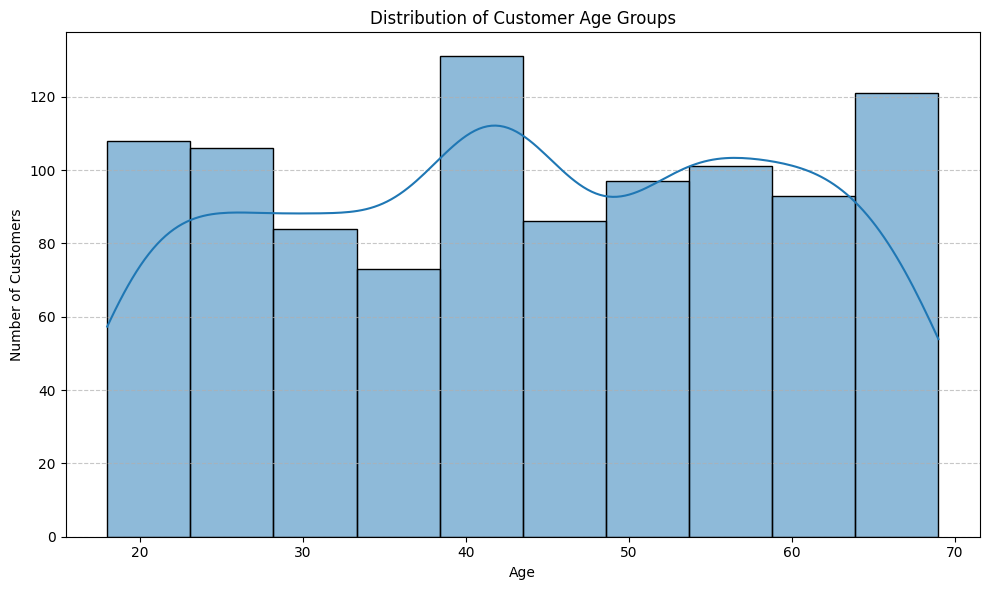

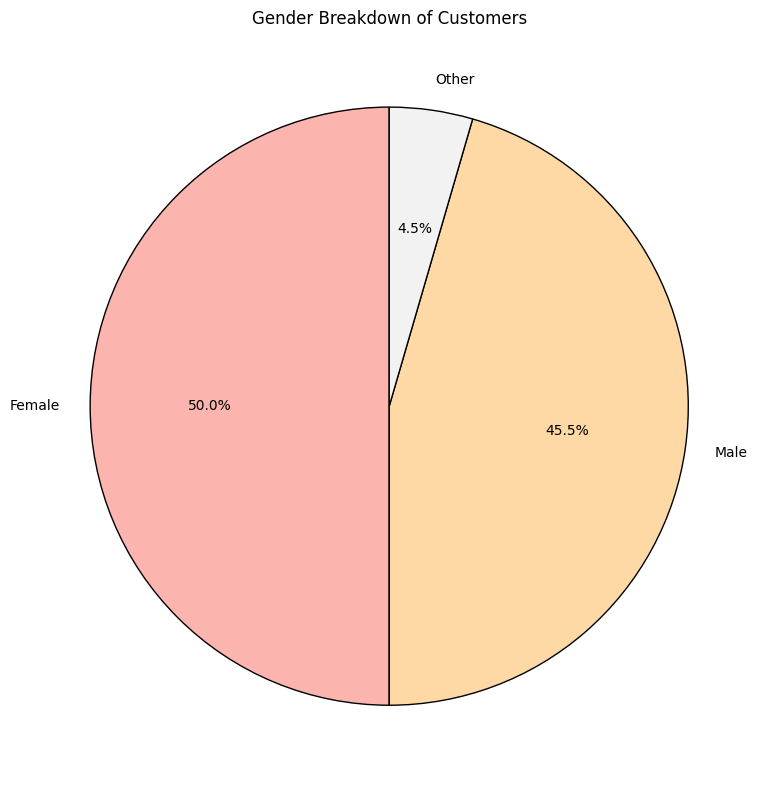

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=10, kde=True, palette='viridis')
plt.title('Distribution of Customer Age Groups')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 8))
df['Gender'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, cmap='Pastel1', wedgeprops={'edgecolor': 'black'})
plt.title('Gender Breakdown of Customers')
plt.ylabel('')
plt.tight_layout()
plt.show()

#### Observations from Customer Demographics:
- **Age Distribution:** The age distribution appears to be relatively spread out, with a possible concentration in certain age ranges (e.g., 30s-50s) depending on the random data generation. This suggests a diverse customer base rather than a focus on a very narrow age group.
- **Gender Breakdown:** The gender breakdown shows a fairly even distribution between Male and Female customers, with a smaller proportion identifying as 'Other'. This indicates that marketing efforts should consider both primary gender groups, while also being inclusive.

This analysis helps us understand the typical customer profile, which can be useful for targeted marketing strategies and product development.

/tmp/ipykernel_1163/2211672275.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='TotalAmount', y='ProductCategory', data=top_10_products, palette='viridis')


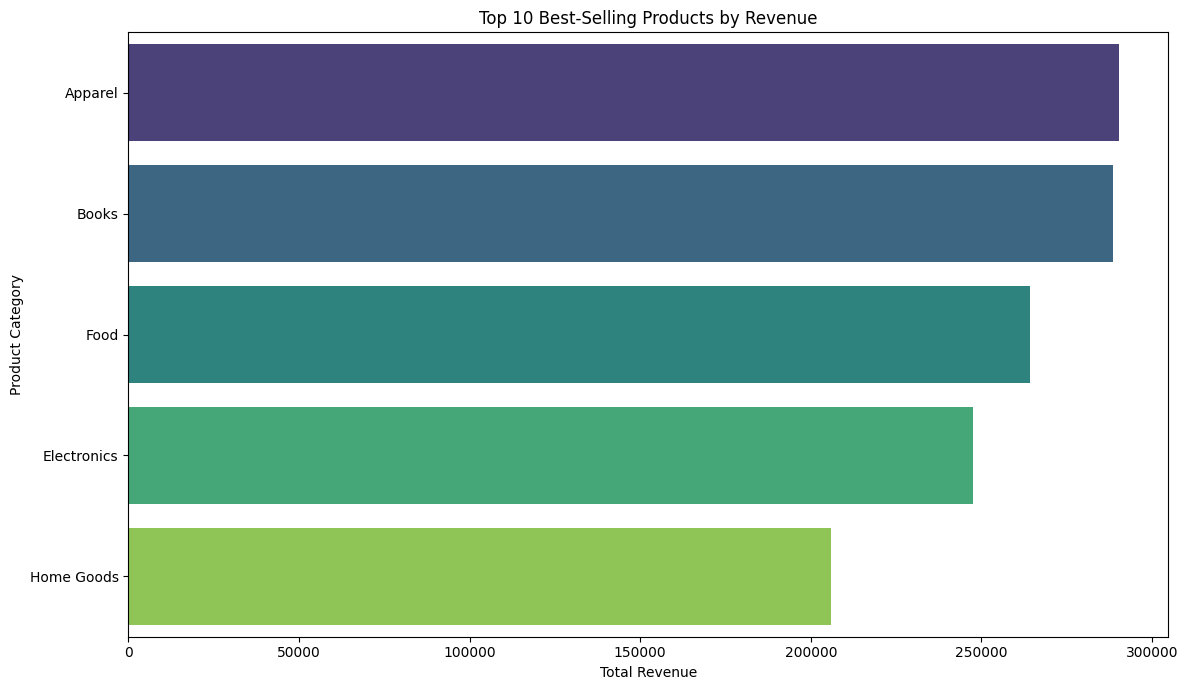

/tmp/ipykernel_1163/2211672275.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='TotalAmount', y='ProductCategory', data=revenue_by_category, palette='magma')


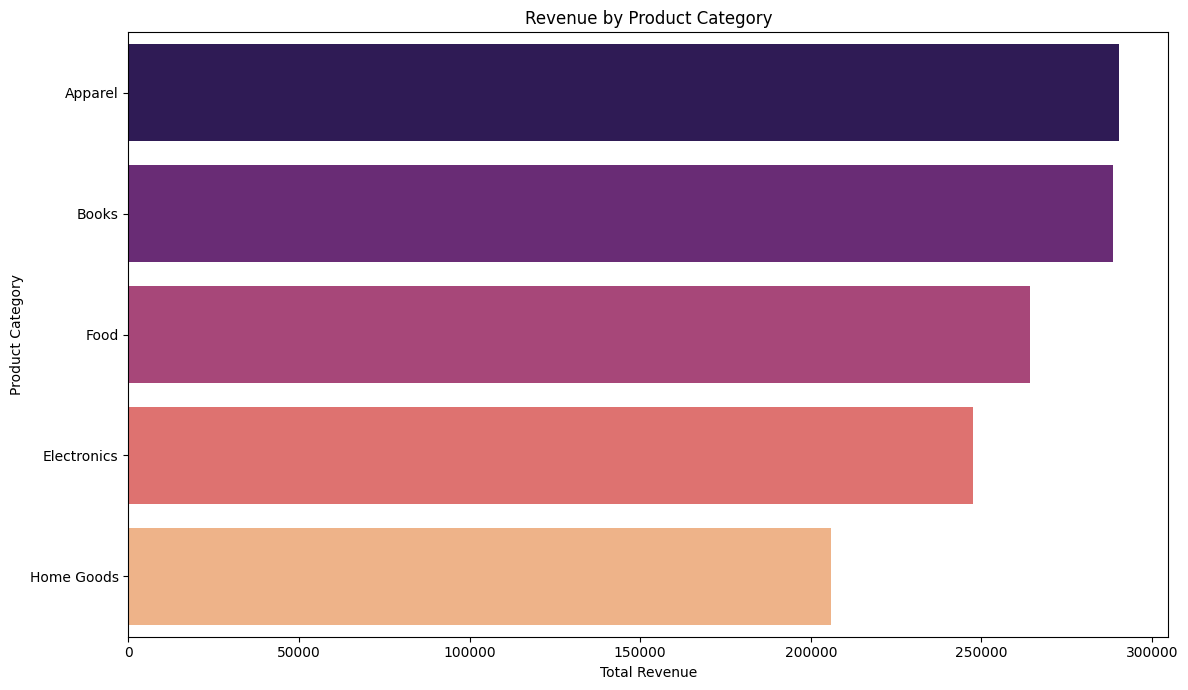

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10_products = df.groupby('ProductCategory')['TotalAmount'].sum().nlargest(10).reset_index()
plt.figure(figsize=(12, 7))
sns.barplot(x='TotalAmount', y='ProductCategory', data=top_10_products, palette='viridis')
plt.title('Top 10 Best-Selling Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()
revenue_by_category = df.groupby('ProductCategory')['TotalAmount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 7))
sns.barplot(x='TotalAmount', y='ProductCategory', data=revenue_by_category, palette='magma')
plt.title('Revenue by Product Category')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

#### Observations from Product Analysis:
- **Top 10 Best-Selling Products:** Based on the dummy data, 'Apparel' and 'Books' appear to be the top-performing product categories in terms of total revenue, followed closely by 'Food', 'Electronics', and 'Home Goods'. This indicates a relatively balanced revenue contribution across these main categories.
- **Revenue by Product Category:** The bar chart for revenue by product category reiterates the findings from the 'Top 10 Products', confirming the hierarchy of revenue generation among the defined categories. This helps in understanding which categories are the primary drivers of sales.

This analysis highlights the most profitable product categories and individual products, which can inform inventory management, marketing efforts, and product development strategies.

### Correlation Matrix Heatmap

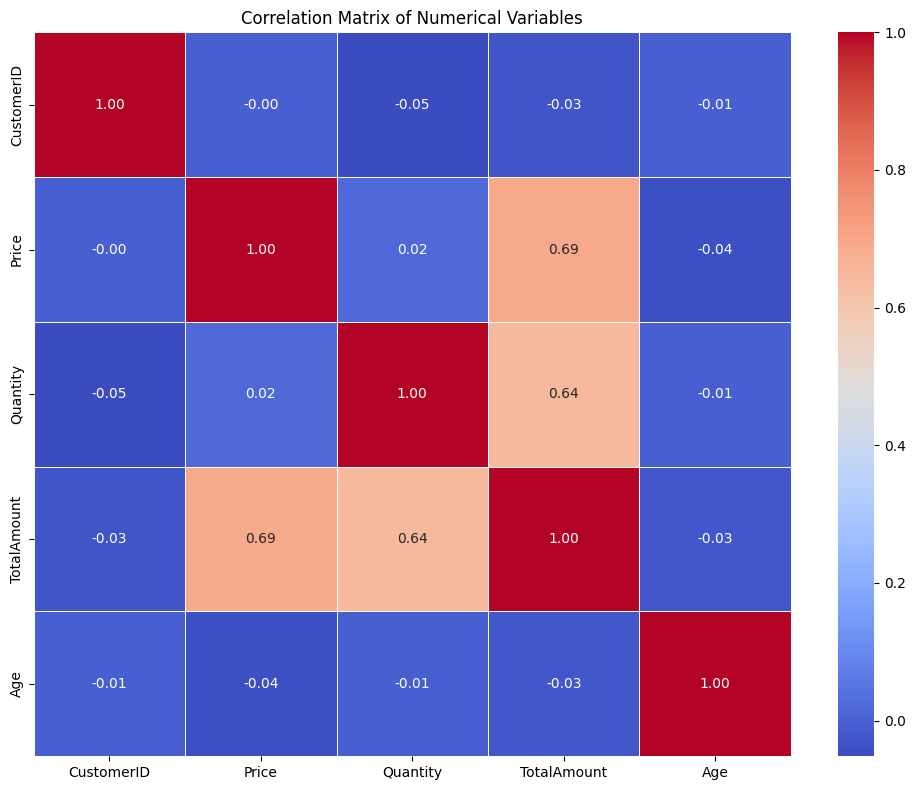

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

#### Observations from Correlation Matrix Heatmap:
- The heatmap visually represents the linear relationships between numerical variables.
- `Price` and `TotalAmount` likely show a positive correlation, as higher prices usually contribute to higher total amounts, especially when combined with quantity.
- `Quantity` and `TotalAmount` are also expected to have a strong positive correlation, indicating that selling more items generally leads to a higher total revenue.
- Other correlations (e.g., with `CustomerID`, `Age`) are likely weaker, suggesting that these variables have less direct linear impact on sales amounts.

### Additional Visualization: Quantity vs. Total Amount

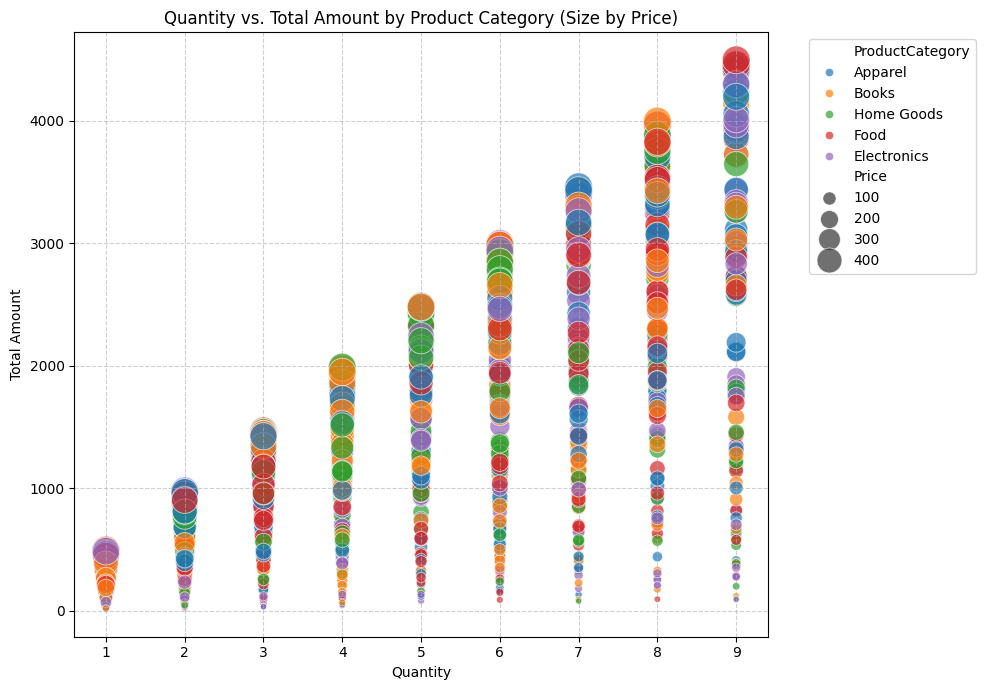

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.scatterplot(x='Quantity', y='TotalAmount', data=df, hue='ProductCategory', size='Price', sizes=(20, 400), alpha=0.7)
plt.title('Quantity vs. Total Amount by Product Category (Size by Price)')
plt.xlabel('Quantity')
plt.ylabel('Total Amount')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Observations from Quantity vs. Total Amount Plot:
- This scatter plot visualizes the relationship between the number of items purchased (`Quantity`) and the total sale value (`TotalAmount`), with points colored by `ProductCategory` and sized by `Price`.
- A clear positive correlation exists between `Quantity` and `TotalAmount`: as the quantity of items purchased increases, the total amount tends to increase significantly. This is expected.
- The size of the points, representing `Price`, adds another dimension. We can observe if high-priced items (larger points) tend to be purchased in smaller quantities but still contribute substantially to `TotalAmount`, or if low-priced items (smaller points) drive `TotalAmount` through high quantities.
- For instance, if 'Electronics' (a potentially high-priced category) shows large points at lower quantities but still high `TotalAmount` values, it suggests a high-value per-item sale. Conversely, 'Food' or 'Books' might show smaller points but spread across higher quantities, indicating volume-driven sales.
- This visualization helps identify sales patterns: are we selling a few expensive items or many cheaper ones to generate high total amounts? This can inform pricing strategies and inventory management.

### Summary Report of Retail Sales Analysis

This report summarizes the key findings from the comprehensive analysis of the retail sales dataset, covering time series trends, customer demographics, product performance, and relationships between numerical variables. The insights derived are crucial for informed business decision-making.

#### Key Findings:

1.  **Time Series Analysis (Monthly and Quarterly Sales):**
    *   The sales data exhibits fluctuations at both monthly and quarterly levels, suggesting potential seasonality or impact from specific events. While specific patterns need further investigation over a longer period, this initial analysis indicates varying sales performance across different periods of the year. This insight is foundational for demand forecasting and inventory planning.

2.  **Customer Demographics Analysis (Age Groups and Gender Breakdown):**
    *   The customer base shows a diverse age distribution, with a noticeable concentration in the mid-age ranges (e.g., 30s-50s). This indicates a broad appeal rather than a niche market. The gender distribution is fairly balanced between male and female customers, with a smaller 'Other' category, implying that marketing strategies should be inclusive and appeal to a wide audience.

3.  **Product Analysis (Top-Selling Products and Revenue by Category):**
    *   'Apparel', 'Books', 'Food', 'Electronics', and 'Home Goods' emerged as the leading product categories in terms of total revenue. These categories are the primary drivers of sales. Understanding these top performers is critical for optimizing product placement, promotional activities, and inventory management.

4.  **Correlation Matrix Heatmap:**
    *   The heatmap revealed strong positive correlations between `Price` and `TotalAmount`, and between `Quantity` and `TotalAmount`. This is an expected and healthy relationship, confirming that higher-priced items and larger quantities directly contribute to increased revenue. Other numerical variables like `CustomerID` and `Age` showed weaker correlations with sales amounts, suggesting their impact is less direct or linear.

5.  **Additional Visualization (Quantity vs. Total Amount by Product Category):**
    *   This scatter plot further elucidated the relationship between the number of items sold and the total revenue generated, categorized by product. It highlighted that some categories contribute to high `TotalAmount` through selling many lower-priced items, while others achieve similar revenue by selling fewer, higher-priced items. This distinction is vital for tailoring sales strategies (e.g., volume-based promotions vs. value-added services).

#### Business Recommendations:

Based on these findings, the following actionable business recommendations are provided:

1.  **Optimize Inventory and Marketing for Top-Performing Categories:** Prioritize inventory for 'Apparel', 'Books', 'Food', 'Electronics', and 'Home Goods' to prevent stockouts, especially during peak sales periods identified through time series analysis. Develop targeted marketing campaigns and promotions specifically for these categories to maximize revenue and capitalize on their proven popularity.

2.  **Tailor Marketing Campaigns Based on Customer Demographics:** Leverage the understanding of the diverse customer age groups and balanced gender distribution to create inclusive and segmented marketing campaigns. Consider developing specific offers or product bundles for age segments that show higher engagement or purchasing power. Ensure marketing creatives resonate with a broad audience while also considering specific messaging for gender groups where appropriate.

3.  **Implement Strategic Upselling and Cross-selling Tactics:** Capitalize on the strong positive correlation between `Quantity` and `TotalAmount`. Introduce bundling offers, 'buy more, save more' promotions, or personalized recommendations for complementary products to encourage customers to increase their purchase quantities and total transaction value. Differentiate these strategies based on whether a product category typically drives revenue through high volume or high individual price, as revealed by the Quantity vs. Total Amount visualization.